# DT2470 Tempo Estimation
## Jupyter Notebook for development and visualisation purposes

In [1]:
import matplotlib.pyplot as plt
from scipy import signal
import soundfile as sf
import numpy as np

params = {'legend.fontsize': 'x-large','figure.figsize': (15, 6),
         'axes.labelsize': 'x-large','axes.titlesize':'x-large',
         'xtick.labelsize':'x-large','ytick.labelsize':'x-large'}
plt.rcParams.update(params)

<class 'numpy.ndarray'>
44100
(1401848,)
31.787936507936507


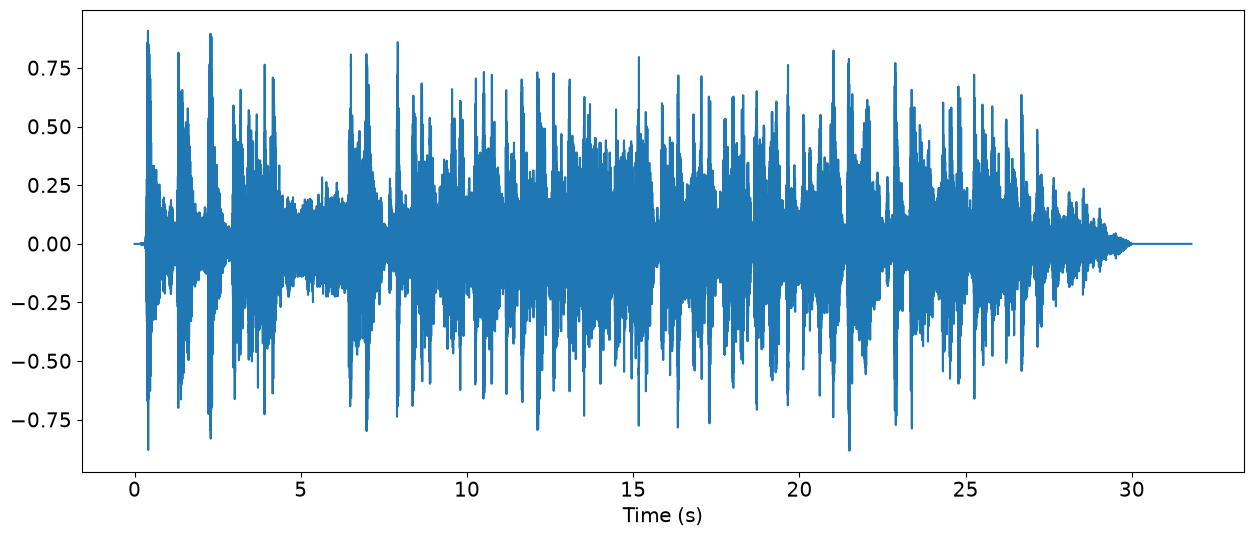

In [2]:
# using a arbitrarily chosen soundfile without vocals for dev purposes
data, sampleRate = sf.read('data/ballroom/B_1.0/audio/Tango/Albums-Ballroom_Classics4-10.wav')
print(type(data))
print(sampleRate)
print(data.shape)

timeLength = data.size/sampleRate
print(timeLength)
timeAxis = np.linspace(0, timeLength, data.size)
plt.plot(timeAxis, data); plt.xlabel("Time (s)")
plt.show()

### Onset Detection
Using spectral based novelty, according to the following steps:
1. STFT
2. Log-compression
3. Differentiation
4. Accumulation along frequencies
5. Normalize by subtracting moving average

#### STFT

In [3]:
windowLen = int(50/1000 * sampleRate)
windowOverlap = int(25/1000 * sampleRate)
freq, time, Z = signal.stft(data, sampleRate, nperseg=windowLen, noverlap=windowOverlap)
magnitude = np.abs(Z)
# eps = 1e-6 
# ZdB = 20 * (np.log10(np.maximum(magnitude, eps)) - np.log10(np.max(magnitude))) 

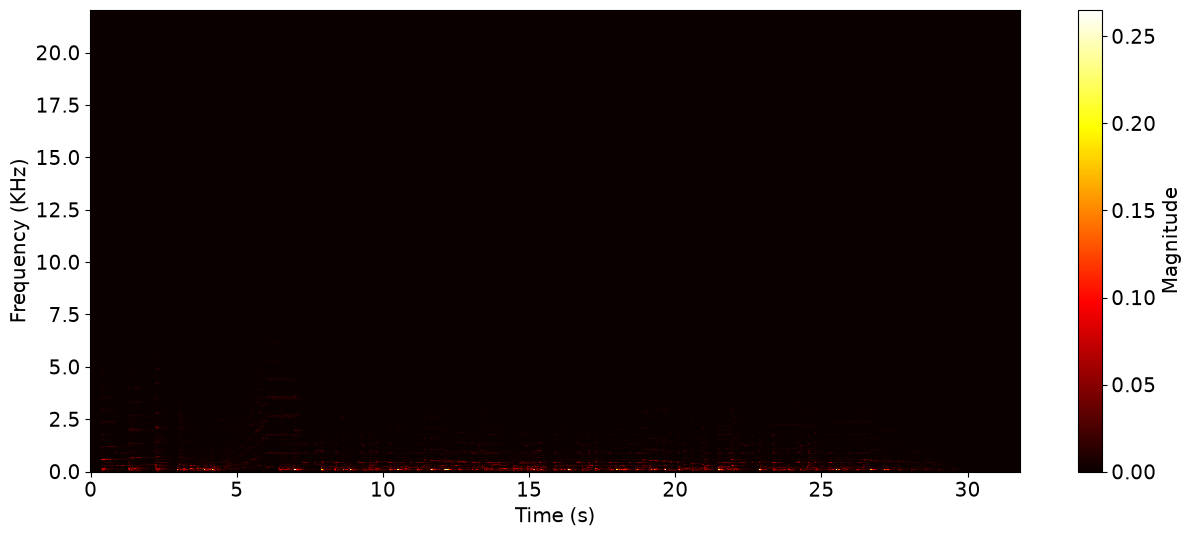

In [10]:
plt.pcolormesh(time, freq/1000, magnitude, cmap='hot')
plt.xlabel("Time (s)"); plt.ylabel("Frequency (KHz)")
plt.colorbar(label="Magnitude")
plt.show()

#### Log-Compression

In [ ]:
# Eq. (6.5)
GAMMA = 1000
magCompressed = np.log(1 + GAMMA * magnitude)

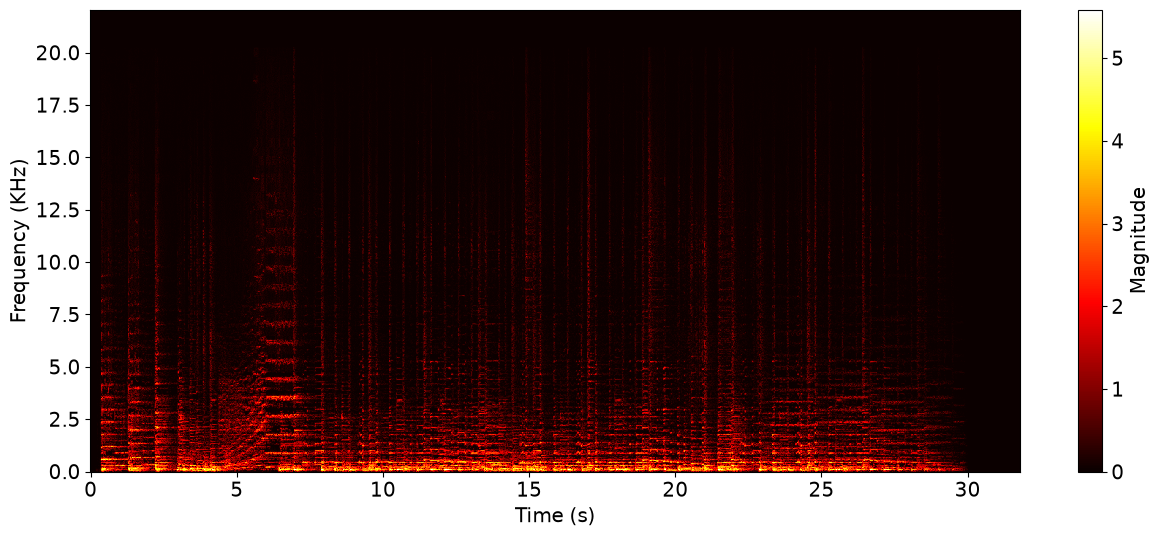

In [9]:
plt.pcolormesh(time, freq/1000, magCompressed, cmap='hot')
plt.xlabel("Time (s)"); plt.ylabel("Frequency (KHz)")
plt.colorbar(label="Magnitude")
plt.show()

#### Differentiation

In [12]:
# Eq. (6.6)
print(magCompressed.shape)

diff = np.diff(magCompressed, n=1, axis=1)
diff[diff<0] = 0

(1103, 1272)


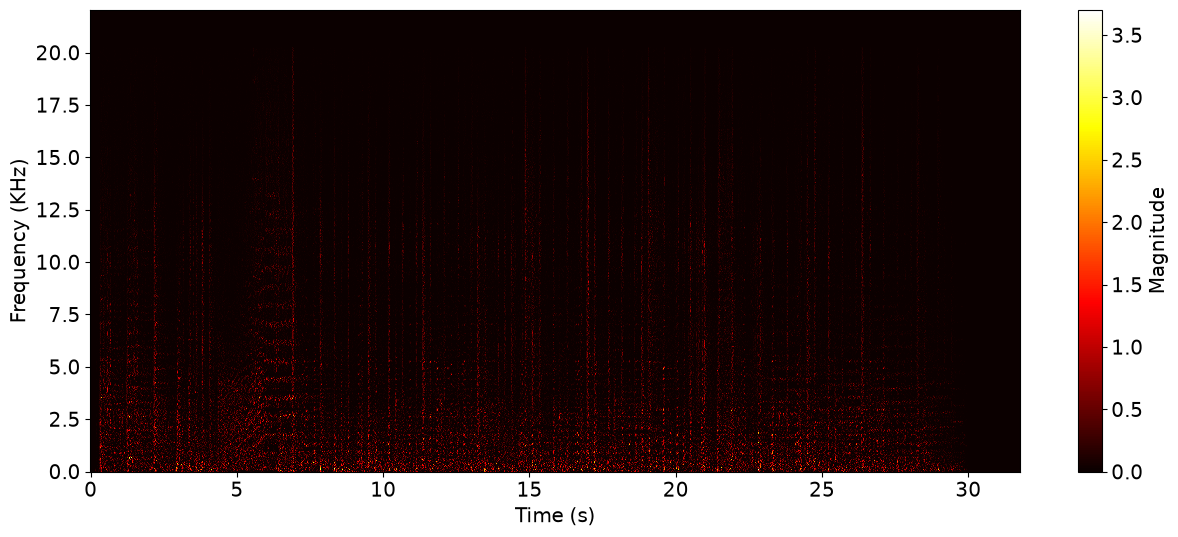

In [11]:
plt.pcolormesh(time[:-1], freq/1000, diff, cmap='hot')
plt.xlabel("Time (s)"); plt.ylabel("Frequency (KHz)")
plt.colorbar(label="Magnitude")
plt.show()

#### Accumulation

In [ ]:
# also Eq. (6.6), just the summation over frequencies
accum = np.sum(diff, axis=0)
print(accum.shape)

(1271,)


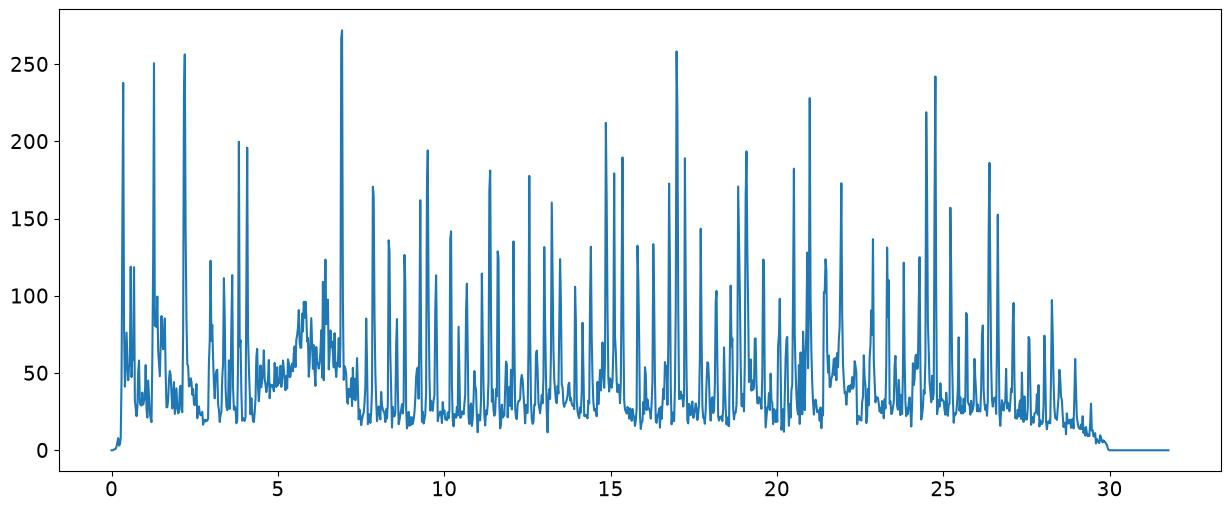

In [15]:
plt.plot(time[:-1], accum); plt.show()

#### Normalization

In [ ]:
# Eq. (6.7) & (6.8)


### Tempograms
